# Import libraries


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import sklearn
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

# Read data

In [ ]:
df = pd.read_csv('train.csv')
df_test = pd.read_csv('test.csv')
df_sample_sumbission = pd.read_csv('sample_submission.csv')

In [ ]:
df.head()

,id,location_type,altitude,area_sq_m,slope_deg,soil_quality,distance_city_center_km,distance_to_school_km,distance_to_hospital_km,distance_to_market_km,...,distance_nearest_park_km,proximity_public_transport,pedestrian_index,employer_density,school_density,hospital_density,amenities_score,price_per_m2,land_area_m2,target
0,id_0,moor,860,384,29.9,0.06,14.7,0.4,6.5,0.2,...,0.59,1,0.24,19.2,2.1,4.9,0.49,19.53,384,8490.76
1,id_1,canyon,1294,543,7.1,0.63,0.8,9.0,9.5,5.2,...,1.23,1,0.62,114.9,12.5,3.8,0.81,21.63,543,13011.02
2,id_2,cliff,1130,1067,5.3,0.77,1.7,5.6,7.8,7.0,...,4.34,1,0.02,54.4,2.9,0.7,0.93,16.70,1067,16913.06
3,id_3,grove,1095,864,34.4,0.99,22.3,8.7,8.0,9.4,...,2.92,1,0.56,11.7,1.6,0.9,0.56,23.73,864,19270.35
4,id_4,grove,1638,1208,30.2,0.01,23.4,8.3,5.3,1.8,...,2.74,1,0.82,69.2,1.7,3.7,0.14,25.15,1208,30719.48


In [ ]:
df.shape

(1500, 45)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 45 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   id                          1500 non-null   object 
 1   location_type               1500 non-null   object 
 2   altitude                    1500 non-null   int64  
 3   area_sq_m                   1500 non-null   int64  
 4   slope_deg                   1500 non-null   float64
 5   soil_quality                1500 non-null   float64
 6   distance_city_center_km     1500 non-null   float64
 7   distance_to_school_km       1500 non-null   float64
 8   distance_to_hospital_km     1500 non-null   float64
 9   distance_to_market_km       1500 non-null   float64
 10  distance_to_industry_km     1500 non-null   float64
 11  proximity_road              1500 non-null   int64  
 12  proximity_water             1500 non-null   int64  
 13  urban_zone                  1500 

In [ ]:
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 44 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   id                          1200 non-null   object 
 1   location_type               1200 non-null   object 
 2   altitude                    1200 non-null   int64  
 3   area_sq_m                   1200 non-null   int64  
 4   slope_deg                   1200 non-null   float64
 5   soil_quality                1200 non-null   float64
 6   distance_city_center_km     1200 non-null   float64
 7   distance_to_school_km       1200 non-null   float64
 8   distance_to_hospital_km     1200 non-null   float64
 9   distance_to_market_km       1200 non-null   float64
 10  distance_to_industry_km     1200 non-null   float64
 11  proximity_road              1200 non-null   int64  
 12  proximity_water             1200 non-null   int64  
 13  urban_zone                  1200 

In [ ]:
df = df.drop(columns='id')
df_test = df_test.drop(columns='id')


In [ ]:
df['location_type'] = LabelEncoder().fit_transform(df['location_type'])
df['land_use'] = LabelEncoder().fit_transform(df['land_use'])
df['zoning_code'] = LabelEncoder().fit_transform(df['zoning_code'])

df_test['location_type'] = LabelEncoder().fit_transform(df_test['location_type'])
df_test['land_use'] = LabelEncoder().fit_transform(df_test['land_use'])
df_test['zoning_code'] = LabelEncoder().fit_transform(df_test['zoning_code'])

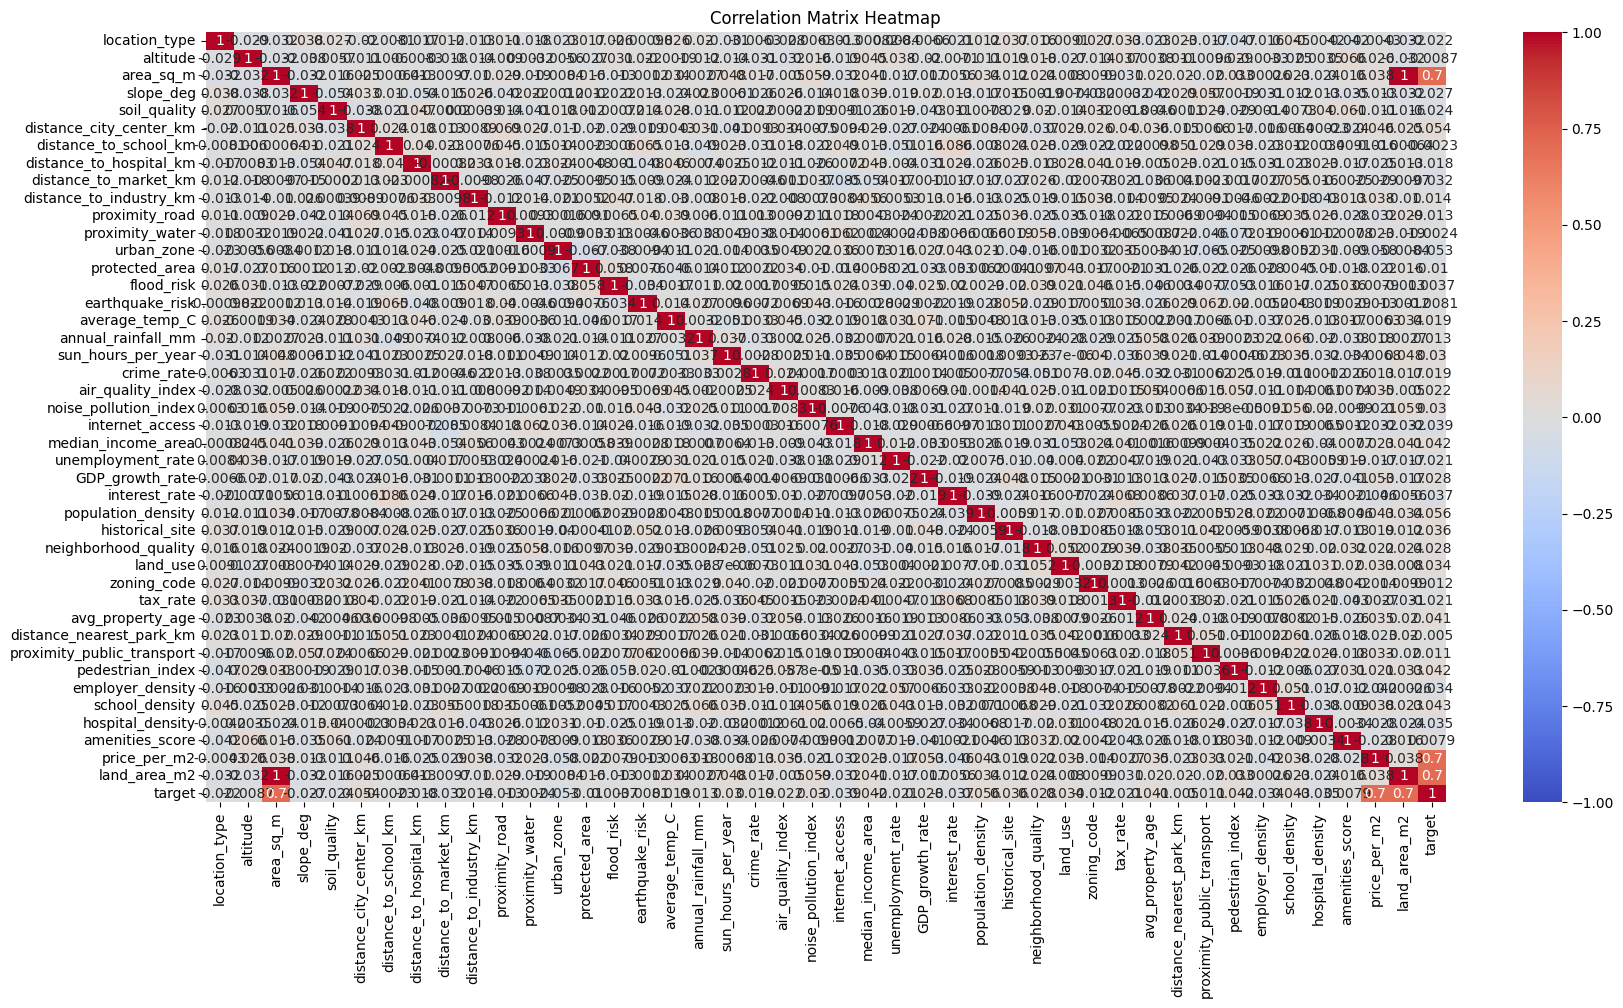

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(20, 10))
# annot=True plots the numerical values inside the blocks
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Correlation Matrix Heatmap")
plt.show()

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 44 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   location_type               1500 non-null   int64  
 1   altitude                    1500 non-null   int64  
 2   area_sq_m                   1500 non-null   int64  
 3   slope_deg                   1500 non-null   float64
 4   soil_quality                1500 non-null   float64
 5   distance_city_center_km     1500 non-null   float64
 6   distance_to_school_km       1500 non-null   float64
 7   distance_to_hospital_km     1500 non-null   float64
 8   distance_to_market_km       1500 non-null   float64
 9   distance_to_industry_km     1500 non-null   float64
 10  proximity_road              1500 non-null   int64  
 11  proximity_water             1500 non-null   int64  
 12  urban_zone                  1500 non-null   int64  
 13  protected_area              1500 

In [ ]:
df.nunique()

,0
location_type,40
altitude,1168
area_sq_m,674
slope_deg,431
soil_quality,101
distance_city_center_km,513
distance_to_school_km,101
distance_to_hospital_km,101
distance_to_market_km,101
distance_to_industry_km,201


In [ ]:
df.describe()

,location_type,altitude,area_sq_m,slope_deg,soil_quality,distance_city_center_km,distance_to_school_km,distance_to_hospital_km,distance_to_market_km,distance_to_industry_km,...,distance_nearest_park_km,proximity_public_transport,pedestrian_index,employer_density,school_density,hospital_density,amenities_score,price_per_m2,land_area_m2,target
count,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,...,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.00000,1500.000000,1500.000000,1500.000000
mean,19.654000,1510.307333,808.857333,22.595333,0.488200,19.870667,5.063467,5.037867,4.949200,10.059333,...,2.562053,0.506000,0.501420,49.273533,4.901467,2.046600,0.49954,20.127753,808.857333,16336.820593
std,11.531707,869.062246,200.558303,12.912443,0.289817,20.115508,2.924687,2.836951,2.891921,5.679881,...,1.451473,0.500131,0.285589,48.672760,4.777578,2.029807,0.28330,4.964707,200.558303,5963.580009
min,0.000000,1.000000,130.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,5.530000,130.000000,1352.530000
25%,9.000000,767.500000,676.000000,11.400000,0.240000,6.075000,2.600000,2.700000,2.500000,5.200000,...,1.300000,0.000000,0.260000,13.800000,1.600000,0.600000,0.26000,16.990000,676.000000,12010.932500
50%,20.000000,1502.000000,809.000000,23.000000,0.480000,14.200000,5.050000,5.100000,4.900000,10.200000,...,2.630000,1.000000,0.500000,34.200000,3.400000,1.500000,0.49000,20.265000,809.000000,15824.475000
75%,30.000000,2221.000000,946.000000,33.825000,0.740000,27.050000,7.600000,7.400000,7.400000,14.900000,...,3.832500,1.000000,0.742500,68.250000,6.700000,2.900000,0.74000,23.502500,946.000000,20174.357500
max,39.000000,2999.000000,1499.000000,44.900000,1.000000,176.000000,10.000000,10.000000,10.000000,20.000000,...,5.000000,1.000000,1.000000,428.200000,34.100000,17.800000,1.00000,36.840000,1499.000000,37781.130000


In [ ]:
X = df.drop(columns=['target'])
y = df['target']

In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
X1 = df['price_per_m2', 'land_area_m2', 'area_sq_m']
y1 = df['price_per_m2', 'land_area_m2', 'area_sq_m', 'target']

In [ ]:
model = LinearRegression()
model.fit(X,y)

LinearRegression()

In [ ]:
model.fit(X1,y1)

In [ ]:
predictions = model.predict(df_test)

In [ ]:
predictions1 = model.predict(df_test)

In [ ]:
predictions

array([ 8241.43171804, 18360.59628046, 13594.97980922, ...,
       20724.59841597, 27748.52299577, 13185.92591396])

In [ ]:
df_sample_sumbission['target'] = predictions
df_sample_sumbission.to_csv('submission.csv', index=False)

In [ ]:
df_sample_sumbission['target'] = predictions1
df_sample_sumbission.to_csv('submission1.csv', index=False)